# NSGA-II — Piloto e implementación, Proyecto 2

## 1. Alcance
Antes de implementar la búsqueda se comprueba si los tres objetivos elegidos sirven para NSGA-II y cuánto costaría correrlo:

| Objetivo | Métrica | Dirección |
|---|---|---|
| Recurso total entregado | `total_resource_obtained` | maximizar |
| Distancia media de ida | `mean_distance_m` | minimizar |
| Presión de competencia | `competition_pressure` | minimizar |

Preguntas: (1) ¿cada objetivo distingue instalaciones más allá del ruido?, (2) ¿alguno es redundante?, (3) ¿el frente resultante es estable?, (4) ¿qué presupuesto es viable?

**Esto no es NSGA-II ni un baseline.** Las instalaciones del piloto solo sirven para diagnosticar los objetivos y no se comparan con RANDOM o GREEDY. El motor es sintético: todo resultado describe el modelo de prueba, no Oslo. Solo se usan las réplicas de búsqueda 1–30; las 31–100 quedan reservadas.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bee_sim").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bee_sim.project2 import load_config
from bee_sim.project2.strategies import nsga2_pilot as pilot
from bee_sim.project2.strategies import nsga2_pilot_plots as plots

pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
cfg = load_config(ROOT / "config/project2/base.yaml")
OBJECTIVES = list(pilot.OBJECTIVES)
FIGURES = ROOT / pilot.PILOT_DIRECTORY / "figures"
FIGURES.mkdir(exist_ok=True)

## 2. Diseño del piloto
Se evalúan 200 instalaciones de K=5 sitios con las mismas 30 semillas (6,000 simulaciones):

- **150 uniformes:** 5 sitios al azar entre los 375 candidatos.
- **50 agrupadas:** un sitio ancla y sus 4 candidatos más cercanos. Se incluyen porque el muestreo uniforme casi nunca junta colmenas, y NSGA-II sí puede explorar esa zona.

La corrida tarda unos 30 minutos, así que no se repite aquí. Se regenera con:

```bash
PYTHONPATH=src python -m bee_sim.project2.strategies.nsga2_pilot
```

`load_pilot` rechaza el archivo si la configuración o el motor cambiaron.

In [2]:
installations, frame, meta = pilot.load_pilot(ROOT / pilot.PILOT_DIRECTORY, cfg)
means = pilot.installation_means(frame, installations)
family = installations.set_index("solution_id").family
uniform = frame[frame.solution_id.map(family) == "uniform"]
clustered = frame[frame.solution_id.map(family) == "clustered"]

print(f"{len(installations)} instalaciones, {frame.replication_id.nunique()} réplicas, {len(frame):,} simulaciones")
print(f"Réplica máxima usada: {frame.replication_id.max()}; métricas vacías: {int(frame[OBJECTIVES].isna().sum().sum())}")
means.groupby("family")[OBJECTIVES].agg(["mean", "min", "max"]).T

200 instalaciones, 30 réplicas, 6,000 simulaciones
Réplica máxima usada: 30; métricas vacías: 0


family                        clustered  uniform
total_resource_obtained mean      371.3    773.3
                        min       119.6    591.2
                        max       774.2    937.8
mean_distance_m         mean      1,794    1,608
                        min       1,518    1,407
                        max       2,213    1,833
competition_pressure    mean   0.001448 0.000289
                        min   0.0003108        0
                        max    0.004298 0.001717

No apareció ninguna métrica vacía, así que el caso sin viajes no se presentó en el piloto. Las agrupadas obtienen mucho menos recurso que las uniformes. Una posible explicación es que sus colmenas alcanzan casi los mismos parches, pero este piloto no lo comprueba.

## 3. ¿Cada objetivo tiene señal?
Como las semillas son comunes, se usa un ANOVA de dos vías (instalación × semilla) que no cuenta el efecto común de cada semilla como ruido. La **fiabilidad** indica qué parte de la diferencia entre medias de instalaciones es real y no azar. Se reporta aparte para las uniformes porque es el caso más difícil: la mezcla con agrupadas infla la variación entre instalaciones.

In [3]:
signal_uniform = pilot.signal_table(uniform, OBJECTIVES)
signal_clustered = pilot.signal_table(clustered, OBJECTIVES)
columns = ["mean", "sd_between", "sd_noise", "reliability", "replications_for_0.9", "zero_run_share"]
display(signal_uniform[columns].style.set_caption("Uniformes").format("{:.4g}"))
display(signal_clustered[columns].style.set_caption("Agrupadas").format("{:.4g}"))

,mean,sd_between,sd_noise,reliability,replications_for_0.9,zero_run_share
metric,,,,,,
total_resource_obtained,773.3,76.04,13.17,0.999,1,0
mean_distance_m,1608,81.91,18.53,0.9983,1,0
competition_pressure,0.000289,0.0002518,0.0005283,0.872,40,0.7591


,mean,sd_between,sd_noise,reliability,replications_for_0.9,zero_run_share
metric,,,,,,
total_resource_obtained,371.3,155.5,4.484,1,1,0
mean_distance_m,1794,158.2,15.2,0.9997,1,0
competition_pressure,0.001448,0.0009622,0.00117,0.953,14,0.298


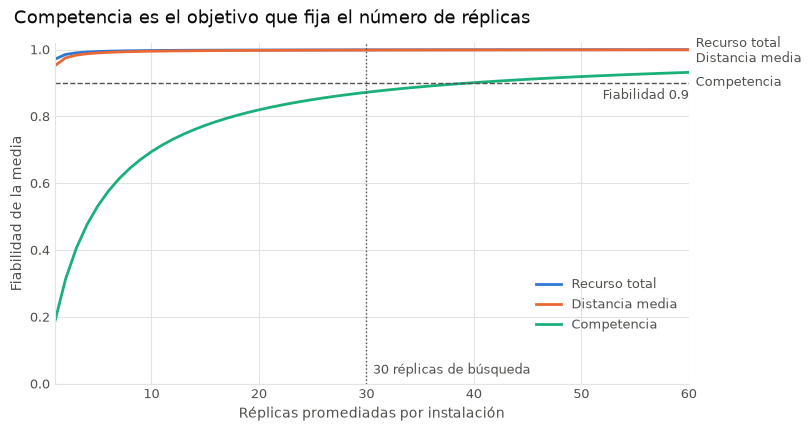

In [4]:
fig = plots.plot_reliability(signal_uniform)
fig.savefig(FIGURES / "pilot_reliability.png", dpi=160)

Recurso y distancia se distinguen casi con una réplica. **Competencia es el objetivo limitante**: en uniformes su ruido es mayor que su señal por corrida, y con 30 réplicas llega a una fiabilidad de 0.87.

La fiabilidad mide si la señal se detecta, no si es grande. La siguiente celda muestra su magnitud.

In [5]:
ATTEMPTS_PER_RUN = cfg["departures_per_day"] * 18 * cfg["K"]  # oportunidades esperadas por corrida
magnitude = pd.DataFrame({
    "presion_media_%": means.groupby("family").competition_pressure.mean() * 100,
    "presion_maxima_%": means.groupby("family").competition_pressure.max() * 100,
    "eventos_por_corrida": means.groupby("family").competition_pressure.mean() * ATTEMPTS_PER_RUN,
    "corridas_en_cero_%": frame.groupby(frame.solution_id.map(family)).competition_pressure.apply(lambda s: s.eq(0).mean() * 100),
})
magnitude

,presion_media_%,presion_maxima_%,eventos_por_corrida,corridas_en_cero_%
clustered,0.1448,0.4298,1.563,29.8
uniform,0.0289,0.1717,0.3121,75.91


La competencia casi no ocurre: menos de un encuentro por corrida en uniformes y como máximo 0.43% de los intentos. Es una consecuencia de los parámetros de prueba: con unos 12 viajes diarios por colonia y alrededor de 1 minuto de forrajeo, las colonias rara vez coinciden en un parche. **No significa que la competencia sea poco importante en Oslo**; un número de viajes realista podría cambiar este resultado.

## 4. ¿Hay objetivos redundantes?
Se usa Spearman entre medias de instalación, con IC 95% por remuestreo de instalaciones. Se separa por familia porque la correlación conjunta mezcla la diferencia entre familias con la relación dentro de cada una.

In [6]:
correlations = pd.concat({
    "uniformes": pilot.correlation_table(means[means.family == "uniform"], OBJECTIVES),
    "agrupadas": pilot.correlation_table(means[means.family == "clustered"], OBJECTIVES),
    "todas": pilot.correlation_table(means, OBJECTIVES),
}, names=["muestra"]).droplevel(1)
correlations

,metric_a,metric_b,n,spearman,ci95_low,ci95_high
muestra,,,,,,
uniformes,total_resource_obtained,mean_distance_m,150,0.003511,-0.1587,0.1747
uniformes,total_resource_obtained,competition_pressure,150,-0.1347,-0.2982,0.03623
uniformes,mean_distance_m,competition_pressure,150,0.1147,-0.05713,0.274
agrupadas,total_resource_obtained,mean_distance_m,50,0.1278,-0.1854,0.4428
agrupadas,total_resource_obtained,competition_pressure,50,0.3213,0.0142,0.5785
agrupadas,mean_distance_m,competition_pressure,50,0.3265,0.07265,0.5327
todas,total_resource_obtained,mean_distance_m,200,-0.3714,-0.4904,-0.2376
todas,total_resource_obtained,competition_pressure,200,-0.5319,-0.6345,-0.4115
todas,mean_distance_m,competition_pressure,200,0.4516,0.312,0.5711


Ningún par es redundante dentro de las uniformes: todas las correlaciones son débiles y sus IC incluyen el cero. Las correlaciones de la muestra conjunta (alrededor de −0.5 entre recurso y competencia) **son un efecto de mezclar familias**, no una relación que deba interpretarse: dentro de las agrupadas ese signo incluso se invierte.

## 5. ¿El frente es estable? ¿Hay un conjunto mejor?
Se compara el conjunto elegido con recurso + distancia solos y con dos alternativas. La **estabilidad** es el índice de Jaccard entre el frente de las réplicas impares y el de las pares: 1 significa que ambas mitades seleccionan las mismas instalaciones. La correlación máxima se calcula en uniformes.

In [7]:
T, D, C = OBJECTIVES
base = {T: "maximize", D: "minimize"}
objective_sets = {
    "recurso + distancia": base,
    "recurso + distancia + competencia": {**base, C: "minimize"},
    "recurso + distancia + mínimo por colmena": {**base, "min_resource_per_hive": "maximize"},
    "recurso + distancia + Jain": {**base, "hive_balance_jain": "maximize"},
}
comparison = pilot.compare_objective_sets(frame, means, objective_sets)
comparison[["front_size", "front_clustered", "shared", "jaccard", "max_abs_spearman"]]

,front_size,front_clustered,shared,jaccard,max_abs_spearman
objectives,,,,,
recurso + distancia,8,0,6,0.75,0.003511
recurso + distancia + competencia,11,0,11,1,0.1347
recurso + distancia + mínimo por colmena,8,0,7,0.875,0.8365
recurso + distancia + Jain,10,0,8,0.7273,0.6741


,total_resource_obtained,mean_distance_m,competition_pressure
solution_id,,,
pilot_184,937.8,"1,571",0.0003404
pilot_113,923.9,"1,533",0.0003464
pilot_176,917.2,"1,516",0.0006488
pilot_101,908.5,"1,494",6.261e-05
pilot_117,902.6,"1,602",0
pilot_193,894.2,"1,516",3.067e-05
pilot_164,891.1,"1,442",0.0007082
pilot_134,843.4,"1,447",0
pilot_109,816.5,"1,434",0.0001237


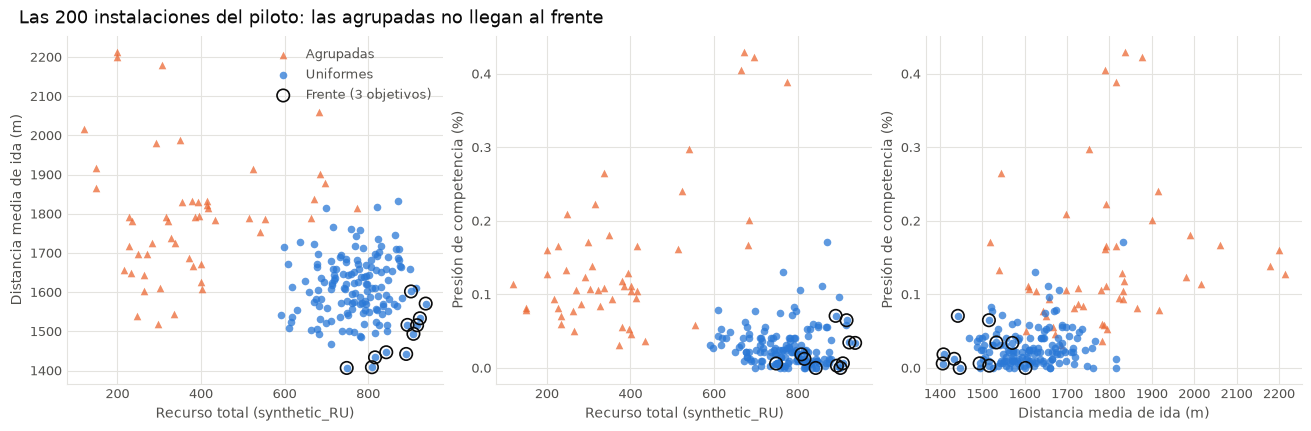

In [8]:
front = pilot.nondominated_mask(means, pilot.OBJECTIVES)
fig = plots.plot_objective_pairs(means, front)
fig.savefig(FIGURES / "pilot_objective_pairs.png", dpi=160)
means[front].sort_values(T, ascending=False)[OBJECTIVES]

El conjunto elegido tiene el frente más estable de los cuatro (mismas 11 instalaciones en ambas mitades) y baja redundancia. Las alternativas no lo mejoran: mínimo por colmena está muy correlacionado con recurso total, y Jain lo está moderadamente y su frente es menos estable.

Esta estabilidad se midió sobre 200 instalaciones muy distintas entre sí. Cerca del frente real las soluciones se parecen más, así que distinguirlas será más difícil de lo que indica esta tabla.

## 6. Presupuesto
Cota superior sin caché con el rendimiento real medido. Una generación evalúa una población completa, además de la población inicial.

In [9]:
print(f"{meta['workers']} procesos: {meta['wall_s'] / 60:.1f} min en total, {meta['wall_s_per_simulation']:.3f} s reales por simulación")
pilot.budget_table(meta["wall_s_per_simulation"], [40, 50], [30, 50, 100])

14 procesos: 29.2 min en total, 0.292 s reales por simulación


,population,generations,replications,simulations,hours
0,40,30,30,37200,3.016
1,40,50,30,61200,4.962
2,40,100,30,121200,9.827
3,50,30,30,46500,3.77
4,50,50,30,76500,6.203
5,50,100,30,151500,12.28


## 7. Conclusiones

1. **Se mantienen los tres objetivos.** No son redundantes, su frente es estable y ninguna alternativa probada es mejor.
2. **Se mantienen 30 réplicas de búsqueda.** Recurso y distancia necesitarían muchas menos, pero competencia cae a una fiabilidad cercana a 0.7 con 10 réplicas.
3. **Presupuesto propuesto:** población 40–50 y 50 generaciones, entre 5 y 6.2 horas sin caché en esta máquina. Con 100 generaciones serían entre 10 y 12 horas.
4. **Limitación de competencia:** es detectable pero casi inexistente con los parámetros de prueba, así que su peso en el frente real será pequeño y no debe presentarse como hallazgo ecológico.
5. **Las instalaciones agrupadas no llegaron al frente** en esta muestra. Es un indicio, no una regla para excluirlas de la búsqueda.

Todo lo anterior vale para el perfil sintético `synthetic_base_v1`. Si cambian los parámetros del motor, hay que repetir el piloto.

## 8. Implementación de NSGA-II
El código está en `src/bee_sim/project2/strategies/nsga2.py` y sus parámetros en `config/project2/strategies/nsga2.yaml`, separados del config común. No usa dependencias nuevas ni modifica el motor.

| Elemento | Decisión |
|---|---|
| Individuo | K sitios distintos en orden canónico; una permutación es la misma instalación |
| Fitness | Media de cada objetivo sobre las réplicas 1–30, con `simulate` |
| Direcciones | Se leen del contrato de métricas |
| Ordenamiento | No dominancia rápida y distancia de hacinamiento |
| Selección | Torneo binario por frente y hacinamiento |
| Cruce | Conserva los sitios comunes y completa con los no comunes de ambos padres |
| Mutación | Cada sitio cambia con probabilidad 1/K por otro candidato fuera de la instalación |
| Reparación | Quita duplicados e IDs ajenos y completa al azar |
| Supervivencia | Elitista (μ + λ) entre padres e hijos |
| Valores vacíos | Cuentan como violación: una solución definida siempre gana a una con vacíos; nunca se sustituyen por cero |
| Parada | Número fijo de generaciones |
| Caché | Por instalación, seed, `config_hash` y `engine_hash` |
| Interrupciones | Guarda el avance por generación y retoma con el mismo RNG |

**Archivo de no dominados.** El frente final no sale de la última población, sino de todo lo evaluado. En las pruebas, cuando el frente exacto era mayor que la población, soluciones dominadas llegaban a la población final; el archivo lo evita sin simulaciones adicionales.

El frente se congela antes de mirar las réplicas 31–100 y no se sobrescribe. Sus medias de búsqueda son optimistas, porque se eligieron con esas mismas réplicas: los valores que se reportan son los de la evaluación reservada.

In [10]:
from bee_sim.project2.strategies import nsga2

parameters = nsga2.load_parameters(ROOT / nsga2.PARAMETERS_FILE)
directions = nsga2.objective_directions(cfg, parameters.objectives)
evaluations = parameters.population * (parameters.generations + 1)
display(pd.Series(directions, name="dirección").to_frame())
print(f"Población {parameters.population}, {parameters.generations} generaciones, {parameters.search_replications} réplicas")
print(f"Cota sin caché: {evaluations * parameters.search_replications:,} simulaciones")

,dirección
total_resource_obtained,maximize
mean_distance_m,minimize
competition_pressure,minimize


Población 50, 50 generaciones, 30 réplicas
Cota sin caché: 76,500 simulaciones


## 9. Ejecución
Los comandos se ejecutan desde la raíz del repositorio. La prueba corta usa su propia carpeta para no mezclarse con la corrida real.

```bash
# prueba de tiempo: 2 generaciones
PYTHONPATH=src python -m bee_sim.project2.strategies.nsga2 search --stop-after 2 --output results/project2/nsga2_trial

# búsqueda completa; si se interrumpe, el mismo comando la retoma
PYTHONPATH=src python -m bee_sim.project2.strategies.nsga2 search

# evaluación final en réplicas 31-100, solo después de congelar el frente
PYTHONPATH=src python -m bee_sim.project2.strategies.nsga2 holdout
```

In [11]:
run_directory = ROOT / nsga2.OUTPUT_DIRECTORY
if (run_directory / "history.csv").exists():
    display(pd.read_csv(run_directory / "history.csv").tail())
else:
    print("Todavía no hay corrida de NSGA-II: esta sección no lanza simulaciones.")

Todavía no hay corrida de NSGA-II: esta sección no lanza simulaciones.
